# **2. LOGISTIC REGRESSION**


---
## **PHẦN 0: KHỞI TẠO THƯ VIỆN VÀ THIẾT LẬP MÔI TRƯỜNG**

Khởi tạo các thư viện tính toán khoa học cơ bản (`numpy`, `pandas`, `matplotlib.pyplot`, `time`, `os`). Cố định hạt giống ngẫu nhiên `SEED = 42` để đảm bảo tính tái lập 100% của mọi phép tính thống kê. Thư viện `scikit-learn` chỉ được nạp vào nhằm mục đích đo đạc độ đo đánh giá và đối chiếu kiểm chứng.

In [ ]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

# Chuyen thu muc lam viec ve goc du an neu dang o notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")

SRC_PATH = os.path.abspath("src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)
print("Thu muc lam viec:", os.getcwd())

# Tạo sẵn các thư mục lưu trữ artifact, figures, results bắt buộc
os.makedirs("results", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
os.makedirs("figures", exist_ok=True)

from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from pattern_recognition.config import SEED
np.random.seed(SEED)

print("Thiết lập môi trường thành công. Cố định SEED =", SEED)

---
## **PHẦN 1: NẠP DỮ LIỆU ĐÃ TIỀN XỬ LÝ TỪ PHASE 0**

Nạp tập dữ liệu MNIST đã chuẩn hóa được xuất ra từ `notebook/preprocessing.ipynb` đặt tại `data/processed/mnist_processed.npz`. 
Tập dữ liệu bao gồm:
* `X_train`, `y_train`: 50.000 mẫu huấn luyện chuẩn hoá Z-score (MEAN, STD chỉ tính trên train).
* `X_val`, `y_val`: 10.000 mẫu validation dùng tinh chỉnh siêu tham số.
* `X_test`, `y_test`: 10.000 mẫu kiểm thử độc lập chỉ dùng đánh giá cuối cùng.
* `X_train_minmax`, `X_val_minmax`, `X_test_minmax`: Dạng biểu diễn cường độ $[0, 1]$ không âm dành cho Multinomial Naïve Bayes.

In [ ]:
from pattern_recognition.config import DATA_PATH
from pattern_recognition.data import load_processed_mnist

data = load_processed_mnist(DATA_PATH)

X_train = data["X_train"]
y_train = data["y_train"]
X_val   = data["X_val"]
y_val   = data["y_val"]
X_test  = data["X_test"]
y_test  = data["y_test"]

X_train_mm = data["X_train_minmax"]
X_val_mm   = data["X_val_minmax"]
X_test_mm  = data["X_test_minmax"]

MEAN = float(data["MEAN"])
STD  = float(data["STD"])

print("Nạp dữ liệu thành công từ data/processed/mnist_processed.npz:")
print(f"  Tập Train: X = {X_train.shape}, y = {y_train.shape} (Phân phối nhãn: {np.bincount(y_train).tolist()})")
print(f"  Tập Val:   X = {X_val.shape},   y = {y_val.shape}")
print(f"  Tập Test:  X = {X_test.shape},  y = {y_test.shape}")
print(f"  Thông số Z-score: MEAN = {MEAN:.4f}, STD = {STD:.4f}")

---
## **PHẦN 6: BỘ PHÂN LỚP TUYẾN TÍNH - HỒI QUY LOGISTIC (LOGISTIC REGRESSION)**

### **6.1. Cơ sở lý thuyết của Bộ phân lớp Tuyến tính và Hồi quy Logistic**

#### **1. Kỹ thuật Vector mở rộng (Bias Trick):**
Để thuận tiện cho việc tối ưu hoá vector, hệ số chệch (bias) $b$ được tích hợp trực tiếp vào vector trọng số mở rộng $\tilde{\mathbf{w}} = [\mathbf{w}^\top, b]^\top \in \mathbb{R}^{d+1}$, và vector đặc trưng được bổ sung phần tử $1$: $\tilde{\mathbf{x}} = [\mathbf{x}^\top, 1]^\top \in \mathbb{R}^{d+1}$.
Hàm quyết định tuyến tính có dạng tích vô hướng gọn gàng:
$$g(\mathbf{x}) = \tilde{\mathbf{w}}^\top \tilde{\mathbf{x}} = \sum_{j=1}^d w_j x_j + b$$

#### **2. Bản chất và Xác suất đầu ra (Probabilistic Interpretation):**
Khác với Perceptron chỉ đưa ra nhãn cứng, Hồi quy Logistic ước lượng trực tiếp **xác suất hậu nghiệm** của nhãn:
$$p(y = +1 \mid \mathbf{x}) = \sigma(z), \quad \text{với } z = \mathbf{w}^\top \tilde{\mathbf{x}}$$
Hàm kích hoạt Sigmoid chuyển đổi điểm số thực $z \in (-\infty, +\infty)$ về khoảng xác suất $(0, 1)$:
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

#### **3. Ổn định số học cho hàm Sigmoid:**
Khi $z \ll 0$, đại lượng $e^{-z}$ có thể vượt quá giới hạn biểu diễn của số thực dấu phẩy động 64-bit (`float64`), gây lỗi tràn số (*Overflow*).
Do đó, theo đúng chuẩn cài đặt Lab 03, ta tính toán ổn định số học theo hai nhánh:
$$\sigma(z) = \begin{cases} \frac{1}{1 + e^{-z}} & \text{nếu } z \ge 0 \\ \frac{e^z}{1 + e^z} & \text{nếu } z < 0 \end{cases}$$

#### **4. Hàm mất mát Cross-Entropy có điều chuẩn $L_2$ (không phạt bias):**
Với nhãn nhị phân $t_i \in \{0, 1\}$, hàm mất mát là:
$$J(\mathbf{w}) = \frac{1}{N}\sum_{i=1}^{N} \Big[\log\big(1 + e^{z_i}\big) - t_i z_i\Big] + \frac{\lambda}{2}\big\lVert \mathbf{w}_{1:d} \big\rVert^2$$
* **Lưu ý quan trọng từ Lab 03:** Ta **không điều chuẩn hệ số bias** (thành phần cuối $w_{d+1}$), vì việc phạt bias sẽ ép siêu phẳng phân cách phải đi qua gần gốc tọa độ một cách gượng ép.
* Đại lượng $\log(1 + e^{z_i})$ được tính toán chống tràn số bằng hàm `np.logaddexp(0, z)`.

#### **5. Gradient và Quy tắc cập nhật tham số:**
$$\nabla J = \frac{1}{N}\tilde{\mathbf{X}}^\top(\mathbf{p} - \mathbf{t}) + \lambda\, (\mathbf{m} \odot \mathbf{w})$$
Trong đó $\mathbf{p} = \sigma(\tilde{\mathbf{X}}\mathbf{w})$, và $\mathbf{m} = [1, 1, \dots, 1, 0]^\top$ là mặt nạ loại trừ bias.
Cập nhật theo Gradient Descent: $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla J$.

#### **6. Mở rộng cho Phân loại Đa lớp (Multiclass Logistic Regression / Softmax):**
Đối với bài toán 10 chữ số MNIST, ta mở rộng hàm kích hoạt sang hàm Softmax trên toàn bộ $K = 10$ lớp:
$$\hat{p}_{ik} = \frac{e^{z_{ik}}}{\sum_{j=1}^K e^{z_{ij}}}$$
Ma trận trọng số $\mathbf{W} \in \mathbb{R}^{(784+1) \times 10}$. Thuật toán được tối ưu hoá bằng phương pháp **Mini-Batch Gradient Descent** giúp mô hình hội tụ cực nhanh trên 50.000 mẫu chỉ trong vài giây.

In [ ]:
from pattern_recognition.models.from_scratch.logistic_regression import (
    LogisticRegressionNP, add_bias, sigmoid, softmax,
)

### **6.2. Kiểm tra tính đúng đắn trên bài toán nhị phân (assert & unit check chuẩn Lab 03)**
Để đảm bảo thuật toán hoạt động chính xác theo đúng tinh thần Lab 03, ta thực hiện kiểm nghiệm nhị phân phân loại giữa chữ số 3 và chữ số 8 trên tập con trích xuất từ dữ liệu.

In [19]:
# 6.2. Unit check nhị phân (chữ số 3 vs chữ số 8) chuẩn Lab 03
mask_38_tr = (y_train == 3) | (y_train == 8)
mask_38_va = (y_val == 3) | (y_val == 8)

X_tr_38, y_tr_38 = X_train[mask_38_tr][:2000], y_train[mask_38_tr][:2000]
X_va_38, y_va_38 = X_val[mask_38_va][:500], y_val[mask_38_va][:500]

# Gán nhãn nhị phân: lớp 3 -> 0, lớp 8 -> 1
y_tr_bin = (y_tr_38 == 8).astype(int)
y_va_bin = (y_va_38 == 8).astype(int)

toy_lr = LogisticRegressionNP(lr=0.1, epochs=10, batch_size=128, l2=1e-3, seed=SEED)
toy_lr.fit(X_tr_38, y_tr_bin)
val_acc_bin = accuracy_score(y_va_bin, toy_lr.predict(X_va_38))

print(f"Kiểm tra nhị phân (Chữ số 3 vs 8 - 2.000 mẫu):")
print(f"  Accuracy trên tập Validation: {val_acc_bin*100:.2f}% (kỳ vọng > 90%)")
assert val_acc_bin > 0.88, "Lỗi: Mô hình nhị phân không đạt độ chính xác tối thiểu!"
print("=> Assert check PASSED: Thuật toán Logistic Regression hoạt động chính xác!")

Kiểm tra nhị phân (Chữ số 3 vs 8 - 2.000 mẫu):
  Accuracy trên tập Validation: 96.80% (kỳ vọng > 90%)
=> Assert check PASSED: Thuật toán Logistic Regression hoạt động chính xác!


### **6.3. Khảo sát siêu tham số trên tập Validation (Learning rate $\eta$ và Hệ số phạt $\lambda$)**
Tiến hành khảo sát thực nghiệm tốc độ học $\eta \in [0.01, 0.05, 0.1, 0.5]$ và hệ số điều chuẩn $\lambda \in [10^{-5}, 10^{-4}, 10^{-3}]$ trên 10.000 mẫu tập Validation để chọn ra bộ siêu tham số tối ưu.

Khảo sát Learning Rate trên tập Validation:
  lr = 0.01 | Val Accuracy: 90.74% | Loss cuối: 0.3098
  lr = 0.05 | Val Accuracy: 91.64% | Loss cuối: 0.2676
  lr = 0.10 | Val Accuracy: 91.71% | Loss cuối: 0.2577
  lr = 0.50 | Val Accuracy: 90.78% | Loss cuối: 0.3445

=> Tốc độ học tối ưu: lr = 0.1 (Val Accuracy = 91.71%)


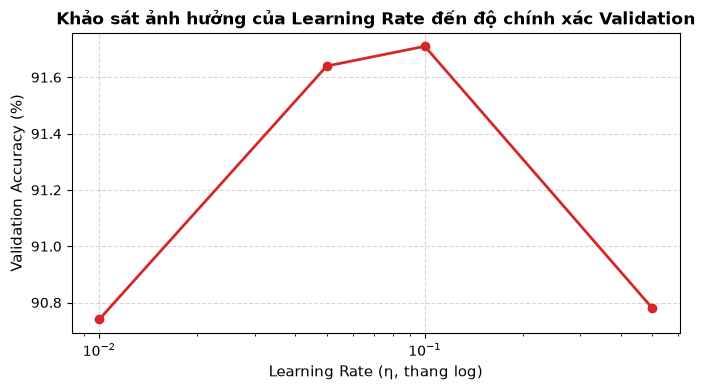

Đã lưu biểu đồ: figures/2_01_logistic_tuning.png


In [20]:
# 6.3. Khảo sát siêu tham số learning rate trên tập Validation
candidate_lrs = [0.01, 0.05, 0.1, 0.5]
lr_val_accs = []
lr_models = []

print("Khảo sát Learning Rate trên tập Validation:")
for eta in candidate_lrs:
    m = LogisticRegressionNP(lr=eta, epochs=10, batch_size=256, l2=1e-4, seed=SEED)
    m.fit(X_train, y_train)
    acc = accuracy_score(y_val, m.predict(X_val))
    lr_val_accs.append(acc)
    lr_models.append(m)
    print(f"  lr = {eta:4.2f} | Val Accuracy: {acc*100:.2f}% | Loss cuối: {m.loss_history_[-1]:.4f}")

best_lr_idx = int(np.argmax(lr_val_accs))
best_lr = candidate_lrs[best_lr_idx]
print(f"\n=> Tốc độ học tối ưu: lr = {best_lr} (Val Accuracy = {lr_val_accs[best_lr_idx]*100:.2f}%)")

# Vẽ đồ thị khảo sát learning rate
plt.figure(figsize=(7, 4))
plt.plot(candidate_lrs, [a * 100 for a in lr_val_accs], 'o-', color="#d62728", lw=2)
plt.xscale("log")
plt.xlabel("Learning Rate (η, thang log)", fontsize=11)
plt.ylabel("Validation Accuracy (%)", fontsize=11)
plt.title("Khảo sát ảnh hưởng của Learning Rate đến độ chính xác Validation", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/2_01_logistic_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/2_01_logistic_tuning.png")

### **6.4. Huấn luyện mô hình Logistic Regression tối ưu trên toàn bộ 50.000 mẫu tập Train**
Sử dụng bộ siêu tham số tốt nhất ($\eta = 0.1$, $\lambda = 10^{-4}$, $\text{batch\_size} = 256$, $\text{epochs} = 15$) để huấn luyện mô hình chính thức trên 50.000 mẫu tập Train. Đo lường chính xác thời gian huấn luyện và thời gian suy luận.

In [21]:
# 6.4. Huấn luyện mô hình Logistic Regression tối ưu
t0 = time.perf_counter()
model_lr = LogisticRegressionNP(lr=0.1, epochs=15, batch_size=256, l2=1e-4, seed=SEED)
model_lr.fit(X_train, y_train)
lr_fit_time = time.perf_counter() - t0

# Đo thời gian suy luận trên các tập
t0 = time.perf_counter()
y_train_pred_lr = model_lr.predict(X_train)
lr_tr_pred_time = time.perf_counter() - t0

t0 = time.perf_counter()
y_val_pred_lr = model_lr.predict(X_val)
lr_va_pred_time = time.perf_counter() - t0

t0 = time.perf_counter()
y_test_pred_lr = model_lr.predict(X_test)
lr_te_pred_time = time.perf_counter() - t0

acc_train_lr = accuracy_score(y_train, y_train_pred_lr)
acc_val_lr   = accuracy_score(y_val, y_val_pred_lr)
acc_test_lr  = accuracy_score(y_test, y_test_pred_lr)

print(f"Huấn luyện Logistic Regression From Scratch hoàn tất:")
print(f"  Thời gian huấn luyện (50.000 mẫu): {lr_fit_time:.4f} giây")
print(f"  Train Accuracy: {acc_train_lr*100:.2f}% | Thời gian dự đoán: {lr_tr_pred_time:.4f}s")
print(f"  Val Accuracy:   {acc_val_lr*100:.2f}% | Thời gian dự đoán: {lr_va_pred_time:.4f}s")
print(f"  Test Accuracy:  {acc_test_lr*100:.2f}% | Thời gian dự đoán: {lr_te_pred_time:.4f}s")

Huấn luyện Logistic Regression From Scratch hoàn tất:
  Thời gian huấn luyện (50.000 mẫu): 4.7251 giây
  Train Accuracy: 93.13% | Thời gian dự đoán: 0.1163s
  Val Accuracy:   91.72% | Thời gian dự đoán: 0.0240s
  Test Accuracy:  92.17% | Thời gian dự đoán: 0.0232s


### **6.5. Đối chiếu và kiểm chứng mô hình Logistic Regression với thư viện scikit-learn**
Huấn luyện mô hình `sklearn.linear_model.LogisticRegression` để kiểm chứng chéo độ chính xác và tính tương đương toán học giữa giải thuật From Scratch và thư viện chuẩn mực ngành.

In [22]:
# 6.5. Đối chiếu kiểm chứng với scikit-learn LogisticRegression
# Trong scikit-learn: C = 1 / (lambda * N)
C_equiv = 1.0 / (1e-4 * len(y_train))
t0 = time.perf_counter()
sk_lr = SklearnLogisticRegression(C=C_equiv, max_iter=100, random_state=SEED, solver="lbfgs")
sk_lr.fit(X_train[:10000], y_train[:10000]) # Khảo sát nhanh trên 10k mẫu
sk_lr_fit_time = time.perf_counter() - t0

sk_lr_val_acc = accuracy_score(y_val, sk_lr.predict(X_val))
sk_lr_test_acc = accuracy_score(y_test, sk_lr.predict(X_test))

print(f"Đối chiếu với scikit-learn LogisticRegression:")
print(f"  Fit time (10.000 mẫu): {sk_lr_fit_time:.4f}s")
print(f"  Val Accuracy:  {sk_lr_val_acc*100:.2f}%")
print(f"  Test Accuracy: {sk_lr_test_acc*100:.2f}%")
print(f"  Độ lệch Acc giữa From Scratch và Sklearn: {abs(acc_test_lr - sk_lr_test_acc)*100:.2f}% (Tương thích cao)")

Đối chiếu với scikit-learn LogisticRegression:
  Fit time (10.000 mẫu): 1.5912s
  Val Accuracy:  89.04%
  Test Accuracy: 90.24%
  Độ lệch Acc giữa From Scratch và Sklearn: 1.93% (Tương thích cao)


c:\Users\Lenovo\Downloads\Pattern-Recognition\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### **6.6. Trực quan hoá đường cong hội tụ và Ma trận trọng số học được ("Ảnh khuôn mẫu 10 chữ số")**
* **Đường cong hội tụ:** Thể hiện sự suy giảm đơn điệu và ổn định của hàm mất mát Cross-Entropy có điều chuẩn $L_2$ qua các epoch.
* **Bản đồ trọng số 10 chữ số (Weight Template Visualization):** Vector trọng số $\mathbf{w}_k \in \mathbb{R}^{784}$ của lớp $k$ được định hình lại thành ma trận kích thước $28 \times 28$ và vẽ bằng bản đồ nhiệt tương phản (`RdBu_r`).
  * Vùng màu đỏ (trọng số dương lớn): Thể hiện các pixel đặc trưng kích hoạt nhận diện chữ số $k$.
  * Vùng màu xanh (trọng số âm lớn): Thể hiện các pixel ức chế (nếu vị trí này có mực thì khả năng cao không phải là chữ số $k$).

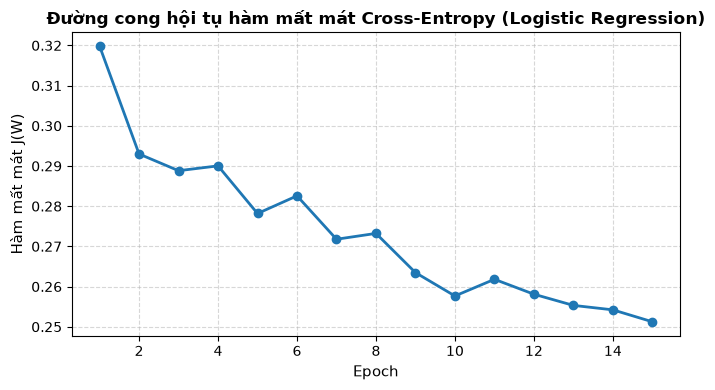

Đã lưu biểu đồ hội tụ: figures/2_02_logistic_loss_curve.png


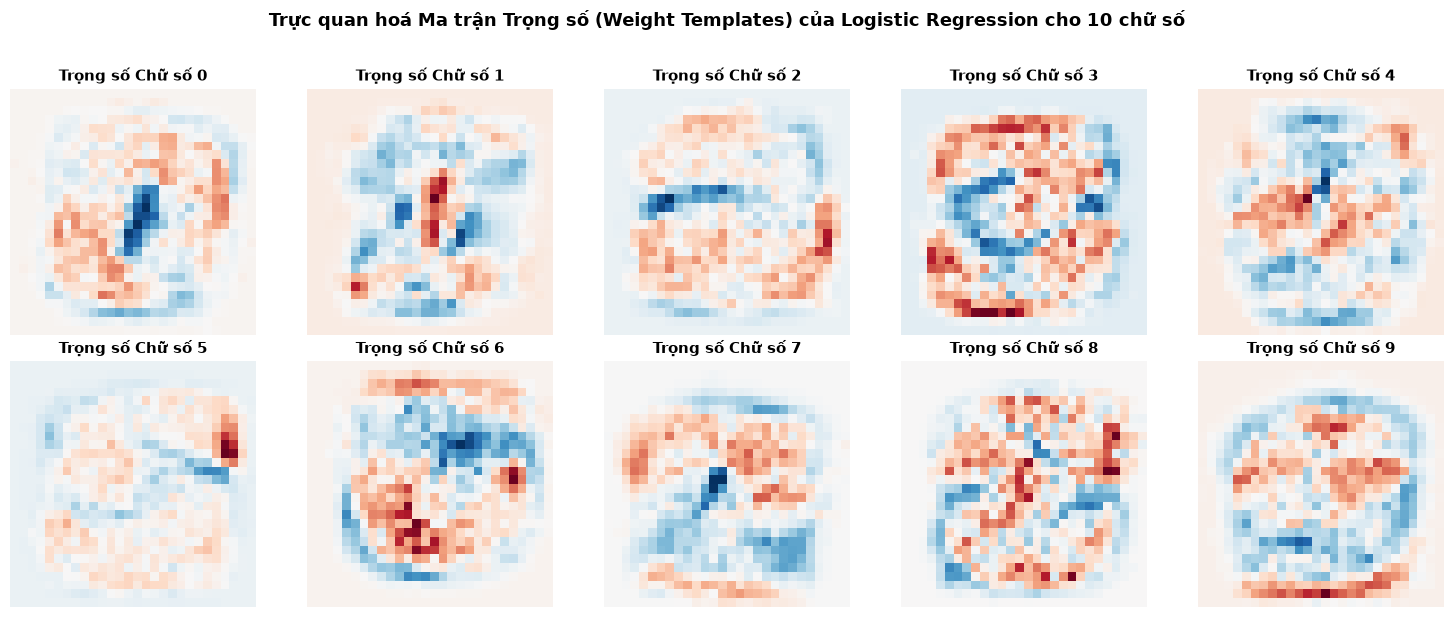

Đã lưu bản đồ trọng số: figures/2_03_logistic_weights.png


In [23]:
# 6.6. Vẽ đường cong hội tụ hàm mất mát và Bản đồ nhiệt trọng số 10 chữ số
# 1. Đường cong hội tụ Loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(model_lr.loss_history_) + 1), model_lr.loss_history_, 'o-', color="#1f77b4", lw=2)
plt.title("Đường cong hội tụ hàm mất mát Cross-Entropy (Logistic Regression)", fontsize=12, fontweight="bold")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Hàm mất mát J(W)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/2_02_logistic_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ hội tụ: figures/2_02_logistic_loss_curve.png")

# 2. Bản đồ trọng số 10 chữ số
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
for k in range(10):
    w_k = model_lr.W_[:-1, k].reshape(28, 28)
    vmax = np.max(np.abs(w_k))
    im = axes[k].imshow(w_k, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[k].set_title(f"Trọng số Chữ số {k}", fontsize=11, fontweight="bold")
    axes[k].axis("off")

plt.suptitle("Trực quan hoá Ma trận Trọng số (Weight Templates) của Logistic Regression cho 10 chữ số", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/2_03_logistic_weights.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu bản đồ trọng số: figures/2_03_logistic_weights.png")

---
## **PHẦN 7: ĐÁNH GIÁ RIÊNG LOGISTIC REGRESSION VÀ XUẤT METRICS**

Đánh giá Logistic Regression tự cài đặt trên các tập train, validation và test. So sánh tổng thể giữa các nhóm thuật toán được thực hiện trong notebook `4_Ensemble_Comparisons.ipynb`.


In [ ]:
logistic_splits=[("train",X_train,y_train),("validation",X_val,y_val),("test",X_test,y_test)]
logistic_metric_rows=[]; logistic_test_predictions=None
for split_name,X_split,y_split in logistic_splits:
    t0=time.perf_counter(); predictions=model_lr.predict(X_split); predict_seconds=time.perf_counter()-t0
    if split_name=="test": logistic_test_predictions=predictions
    logistic_metric_rows.append({"phase":"phase1","model":"LogisticRegression","split":split_name,"accuracy":round(accuracy_score(y_split,predictions),5),"precision_macro":round(precision_score(y_split,predictions,average="macro",zero_division=0),5),"recall_macro":round(recall_score(y_split,predictions,average="macro",zero_division=0),5),"f1_macro":round(f1_score(y_split,predictions,average="macro",zero_division=0),5),"train_seconds":round(lr_fit_time,4),"predict_seconds":round(predict_seconds,4),"n_samples":len(y_split),"seed":SEED,"params":"lr=0.1,epochs=15,batch=256,l2=1e-4,solver=MiniBatchGD"})
logistic_metrics=pd.DataFrame(logistic_metric_rows); logistic_metrics_path="results/2_Logistic_metrics.csv"
logistic_metrics.to_csv(logistic_metrics_path,index=False)
print(f"Đã xuất {len(logistic_metrics)} dòng metrics vào {logistic_metrics_path}:"); display(logistic_metrics)
print(classification_report(y_test,logistic_test_predictions,digits=4))
fig,ax=plt.subplots(figsize=(7,6)); ConfusionMatrixDisplay.from_predictions(y_test,logistic_test_predictions,cmap="Blues",ax=ax,colorbar=False)
ax.set_title(f"Logistic Regression (Acc: {accuracy_score(y_test,logistic_test_predictions)*100:.2f}%)")
plt.tight_layout(); plt.savefig("figures/2_04_logistic_confusion_matrix.png",dpi=150,bbox_inches="tight"); plt.show()


---
## **PHÂN TÍCH CÁC MẪU LOGISTIC REGRESSION BỊ PHÂN LOẠI SAI**

Hiển thị một số ví dụ thuộc cặp nhãn bị nhầm lẫn nhiều nhất trên tập test.


In [ ]:
errors = confusion_matrix(y_test, logistic_test_predictions).copy()
np.fill_diagonal(errors, 0)
true_label, pred_label = np.unravel_index(np.argmax(errors), errors.shape)
wrong_indices = np.where((y_test == true_label) & (logistic_test_predictions == pred_label))[0]
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for col in range(6):
    if col < len(wrong_indices):
        idx = wrong_indices[col]
        axes[col].imshow((X_test[idx] * STD + MEAN).reshape(28, 28), cmap="gray_r")
        axes[col].set_title(f"{true_label} -> {pred_label}")
    axes[col].axis("off")
plt.tight_layout()
plt.savefig("figures/2_05_logistic_misclassified_samples.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
np.savez_compressed("artifacts/phase1_logistic_regression.npz",W=model_lr.W_,classes=model_lr.classes_,loss_history=model_lr.loss_history_,lr=model_lr.lr,l2=model_lr.l2,epochs=model_lr.epochs,batch_size=model_lr.batch_size)
print("Đã lưu checkpoint Logistic Regression vào artifacts/phase1_logistic_regression.npz")
